In [1]:

# ══════════════════════════════════════════════════════
# CELL 1 — IMPORTS
# ══════════════════════════════════════════════════════
import os, io, json, glob, shutil, warnings
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image as keras_image
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

warnings.filterwarnings('ignore')
tf.get_logger().setLevel('ERROR')
print('✅ Imports done')

/Users/parthbarot/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


✅ Imports done


In [2]:
# ══════════════════════════════════════════════════════
# CELL 2 — CONFIGURATION  (edit only this cell)
# ══════════════════════════════════════════════════════
CONFIG = {
    # Paths
    'source_dir'           : './dataset',
    'train_dir'            : './dataset/train',
    'val_dir'              : './dataset/val',
    'test_dir'             : './dataset/test',
    'model_path'           : 'agri_sarthi_model.keras',
    'class_idx_path'       : 'class_indices.json',

    # Classes — add more strings here when you scale up
    'classes'              : [
        'Apple___healthy',
        'Apple___Apple_scab',
        'Apple___Black_rot',
        'Apple___Cedar_apple_rust',
        'Tomato___healthy',
        'Tomato___Bacterial_spot',
        'Tomato___Early_blight',
        'Tomato___Late_blight',
        'Tomato___Leaf_Mold',
        'Tomato___Septoria_leaf_spot',
        'Tomato___Spider_mites Two-spotted_spider_mite',
        'Tomato___Target_Spot',
        'Tomato___Tomato_mosaic_virus',
        'Tomato___Tomato_Yellow_Leaf_Curl_Virus',
    ],

    # Training hyper-parameters
    'img_size'             : (224, 224),
    'batch_size'           : 32,
    'epochs'               : 30,
    'patience'             : 7,
    'learning_rate'        : 1e-3,

    # Prediction
    'confidence_threshold' : 0.70,
}

CLASS_NAMES = CONFIG['classes']
print('✅ Config ready — classes:', CLASS_NAMES)

✅ Config ready — classes: ['Apple___healthy', 'Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Tomato___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_mosaic_virus', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus']


In [3]:
# ══════════════════════════════════════════════════════
# CELL 3 — DATASET SPLIT  (70 / 15 / 15)
# ══════════════════════════════════════════════════════
def prepare_dataset(cfg: dict) -> None:
    """
    Copies images from ./dataset/<class>/ into
    train / val / test sub-folders (70 / 15 / 15 split).
    Skips a class if its train folder is already populated
    to avoid running twice and doubling the files.
    """
    for split in ['train', 'val', 'test']:
        for cls in cfg['classes']:
            os.makedirs(os.path.join(cfg[f'{split}_dir'], cls), exist_ok=True)

    print('=' * 54)
    print('  Dataset Preparation  (70 / 15 / 15)')
    print('=' * 54)

    for cls in cfg['classes']:
        dest_train = os.path.join(cfg['train_dir'], cls)

        if len(os.listdir(dest_train)) > 0:
            print(f'  ↩  {cls:<44} — already split, skipping')
            continue

        src = os.path.join(cfg['source_dir'], cls)
        imgs = (
            glob.glob(f'{src}/*.[jJ][pP][gG]')
            + glob.glob(f'{src}/*.[jJ][pP][eE][gG]')
            + glob.glob(f'{src}/*.[pP][nN][gG]')
        )

        if not imgs:
            print(f'  ⚠  No images found in: {src}')
            continue

        train_imgs, temp      = train_test_split(imgs, test_size=0.30, random_state=42)
        val_imgs,   test_imgs = train_test_split(temp, test_size=0.50, random_state=42)

        for img_list, split_key in [
            (train_imgs, 'train_dir'),
            (val_imgs,   'val_dir'),
            (test_imgs,  'test_dir'),
        ]:
            dest_dir = os.path.join(cfg[split_key], cls)
            for f in img_list:
                shutil.copy2(f, dest_dir)

        print(
            f'  ✓  {cls:<44}  '
            f'train={len(train_imgs):>4}  '
            f'val={len(val_imgs):>3}  '
            f'test={len(test_imgs):>3}'
        )

    print('=' * 54)
    print('  Dataset preparation complete!\n')


prepare_dataset(CONFIG)

  Dataset Preparation  (70 / 15 / 15)
  ↩  Apple___healthy                              — already split, skipping
  ↩  Apple___Apple_scab                           — already split, skipping
  ↩  Apple___Black_rot                            — already split, skipping
  ↩  Apple___Cedar_apple_rust                     — already split, skipping
  ↩  Tomato___healthy                             — already split, skipping
  ↩  Tomato___Bacterial_spot                      — already split, skipping
  ↩  Tomato___Early_blight                        — already split, skipping
  ↩  Tomato___Late_blight                         — already split, skipping
  ↩  Tomato___Leaf_Mold                           — already split, skipping
  ↩  Tomato___Septoria_leaf_spot                  — already split, skipping
  ↩  Tomato___Spider_mites Two-spotted_spider_mite — already split, skipping
  ↩  Tomato___Target_Spot                         — already split, skipping
  ↩  Tomato___Tomato_mosaic_virus                

In [4]:
# ══════════════════════════════════════════════════════
# CELL 4 — DATA GENERATORS + AUGMENTATION
# ══════════════════════════════════════════════════════
def build_generators(cfg: dict):
    """
    Training  → augmented  (rotation, flip, zoom, brightness, shifts)
    Val/Test  → rescale only  (no augmentation — clean evaluation)
    """
    train_aug = ImageDataGenerator(
        rescale            = 1.0 / 255,
        rotation_range     = 25,
        width_shift_range  = 0.2,
        height_shift_range = 0.2,
        shear_range        = 0.15,
        zoom_range         = 0.2,
        brightness_range   = [0.8, 1.2],
        horizontal_flip    = True,
        fill_mode          = 'nearest',
    )
    plain = ImageDataGenerator(rescale=1.0 / 255)

    train_gen = train_aug.flow_from_directory(
        cfg['train_dir'], target_size=cfg['img_size'],
        batch_size=cfg['batch_size'], class_mode='categorical', shuffle=True,
    )
    val_gen = plain.flow_from_directory(
        cfg['val_dir'], target_size=cfg['img_size'],
        batch_size=cfg['batch_size'], class_mode='categorical', shuffle=False,
    )
    test_gen = plain.flow_from_directory(
        cfg['test_dir'], target_size=cfg['img_size'],
        batch_size=cfg['batch_size'], class_mode='categorical', shuffle=False,
    )

    print(f'  Training   samples : {train_gen.samples}')
    print(f'  Validation samples : {val_gen.samples}')
    print(f'  Test       samples : {test_gen.samples}\n')
    return train_gen, val_gen, test_gen


train_gen, val_gen, test_gen = build_generators(CONFIG)

Found 14925 images belonging to 14 classes.
Found 3200 images belonging to 14 classes.
Found 3206 images belonging to 14 classes.
  Training   samples : 14925
  Validation samples : 3200
  Test       samples : 3206



In [5]:
# ══════════════════════════════════════════════════════
# CELL 5 — MODEL  (MobileNetV2 + custom head)
# ══════════════════════════════════════════════════════
def build_model(num_classes: int = 14) -> Model:
    """
    Frozen MobileNetV2 (pretrained on ImageNet) as feature extractor.
    Custom dense head on top for our leaf classes.
    Far better accuracy than training a CNN from scratch.
    """
    base = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
    base.trainable = False

    x = base.output
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)
    x = Dense(512, activation='relu')(x)
    x = Dropout(0.4)(x)
    x = Dense(256, activation='relu')(x)
    x = Dropout(0.3)(x)
    output = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs=base.input, outputs=output)
    model.compile(
        optimizer = tf.keras.optimizers.Adam(learning_rate=CONFIG['learning_rate']),
        loss      = 'categorical_crossentropy',
        metrics   = ['accuracy'],
    )

    trainable = sum(tf.size(w).numpy() for w in model.trainable_weights)
    print(f'  Total parameters     : {model.count_params():,}')
    print(f'  Trainable parameters : {trainable:,}\n')
    return model


model = build_model(num_classes=len(CLASS_NAMES))

2026-05-02 09:59:36.708979: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4
2026-05-02 09:59:36.709011: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-05-02 09:59:36.709015: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-05-02 09:59:36.709051: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-05-02 09:59:36.709060: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


  Total parameters     : 3,053,902
  Trainable parameters : 793,358



In [6]:
# ══════════════════════════════════════════════════════
# CELL 6 — CALLBACKS
# ══════════════════════════════════════════════════════
callbacks = [
    # Stop training if val_accuracy doesn't improve for `patience` epochs
    EarlyStopping(
        monitor='val_accuracy', patience=CONFIG['patience'],
        restore_best_weights=True, verbose=1,
    ),
    # Halve learning rate when val_loss plateaus for 3 epochs
    ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1,
    ),
    # Save only the best model (by val_accuracy)
    ModelCheckpoint(
        filepath=CONFIG['model_path'], monitor='val_accuracy',
        save_best_only=True, verbose=1,
    ),
]
print('✅ Callbacks ready')

✅ Callbacks ready


In [7]:
# ══════════════════════════════════════════════════════
# CELL 7 — TRAINING
# ══════════════════════════════════════════════════════
print('=' * 54)
print('  Training  (max', CONFIG['epochs'], 'epochs)')
print('=' * 54)

history = model.fit(
    train_gen,
    epochs          = CONFIG['epochs'],
    validation_data = val_gen,
    callbacks       = callbacks,
    verbose         = 1,
)

# Save class indices → { "Apple___healthy": 0, "Tomato___healthy": 1, ... }
with open(CONFIG['class_idx_path'], 'w') as f:
    json.dump(train_gen.class_indices, f, indent=2)

print(f'\n✅ Best model saved  → {CONFIG["model_path"]}')
print(f'✅ Class indices     → {CONFIG["class_idx_path"]}\n')

  Training  (max 30 epochs)
Epoch 1/30


2026-05-02 09:59:38.497675: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


467/467 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.6362 - loss: 1.9561
Epoch 1: val_accuracy improved from -inf to 0.81656, saving model to agri_sarthi_model.keras
467/467 ━━━━━━━━━━━━━━━━━━━━ 79s 161ms/step - accuracy: 0.6363 - loss: 1.9557 - val_accuracy: 0.8166 - val_loss: 0.9878 - learning_rate: 0.0010
Epoch 2/30
467/467 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - accuracy: 0.7578 - loss: 1.6151
Epoch 2: val_accuracy improved from 0.81656 to 0.85250, saving model to agri_sarthi_model.keras
467/467 ━━━━━━━━━━━━━━━━━━━━ 77s 166ms/step - accuracy: 0.7578 - loss: 1.6151 - val_accuracy: 0.8525 - val_loss: 0.8635 - learning_rate: 0.0010
Epoch 3/30
467/467 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - accuracy: 0.7738 - loss: 1.6045
Epoch 3: val_accuracy improved from 0.85250 to 0.87437, saving model to agri_sarthi_model.keras
467/467 ━━━━━━━━━━━━━━━━━━━━ 89s 190ms/step - accuracy: 0.7738 - loss: 1.6046 - val_accuracy: 0.8744 - val_loss: 0.7037 - learning_rate: 0.0010
Epoch 4/30
467/467 ━━━━━━━━━━━

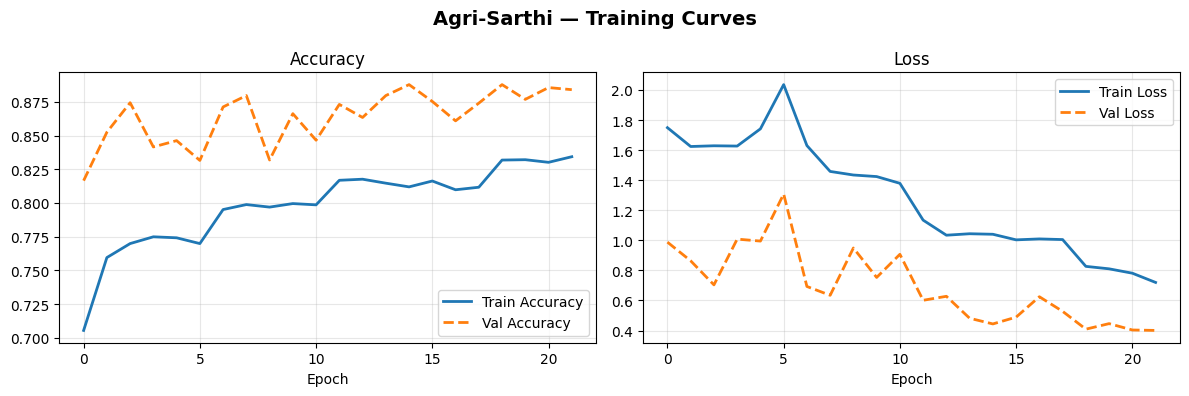

📊 Training curves saved → training_curves.png



In [8]:
# ══════════════════════════════════════════════════════
# CELL 8 — TRAINING CURVES
# ══════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Agri-Sarthi — Training Curves', fontsize=14, fontweight='bold')

for ax, metric, title in [
    (axes[0], 'accuracy', 'Accuracy'),
    (axes[1], 'loss',     'Loss'),
]:
    ax.plot(history.history[metric],           label=f'Train {title}', linewidth=2)
    ax.plot(history.history[f'val_{metric}'],  label=f'Val {title}',   linewidth=2, linestyle='--')
    ax.set_title(title)
    ax.set_xlabel('Epoch')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('📊 Training curves saved → training_curves.png\n')

  Evaluation
  Validation    Accuracy: 0.8878   Loss: 0.4439
  Test          Accuracy: 0.8915   Loss: 0.5074

  Classification Report (Test set):
                                               precision    recall  f1-score   support

                              Apple___healthy       0.97      0.91      0.93        95
                           Apple___Apple_scab       0.98      0.97      0.97        94
                            Apple___Black_rot       1.00      0.98      0.99        42
                     Apple___Cedar_apple_rust       0.96      0.99      0.98       247
                             Tomato___healthy       0.87      0.88      0.87       320
                      Tomato___Bacterial_spot       0.83      0.63      0.71       150
                        Tomato___Early_blight       0.94      0.89      0.92       287
                         Tomato___Late_blight       0.71      0.88      0.79       143
                           Tomato___Leaf_Mold       0.74      0.91    

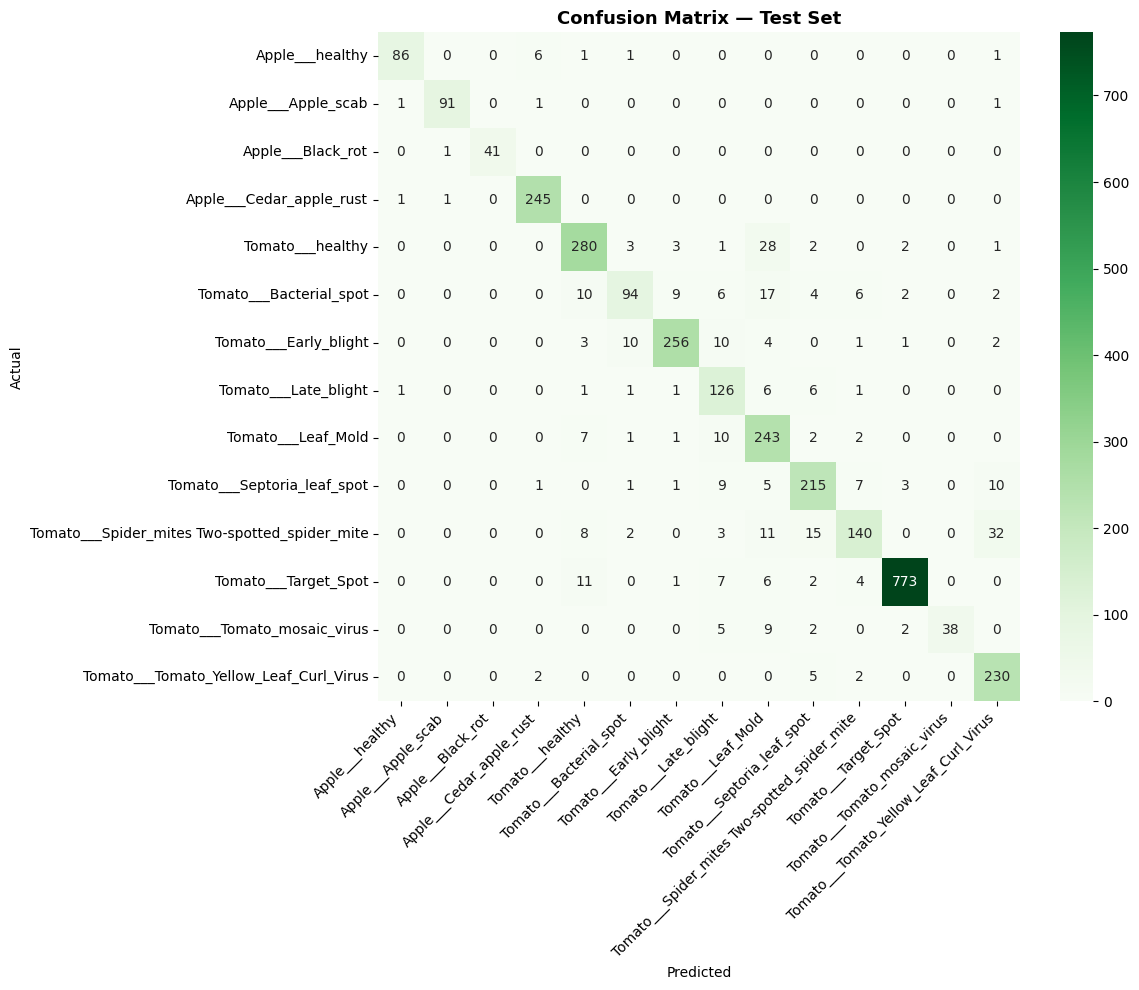

📊 Confusion matrix saved → confusion_matrix.png



In [9]:
# ══════════════════════════════════════════════════════
# CELL 9 — EVALUATION + CONFUSION MATRIX
# ══════════════════════════════════════════════════════
print('=' * 54)
print('  Evaluation')
print('=' * 54)

for name, gen in [('Validation', val_gen), ('Test', test_gen)]:
    loss, acc = model.evaluate(gen, verbose=0)
    print(f'  {name:<12}  Accuracy: {acc:.4f}   Loss: {loss:.4f}')

# Full classification report on test set
test_gen.reset()
y_pred = np.argmax(model.predict(test_gen, verbose=0), axis=1)
y_true = test_gen.classes

print('\n  Classification Report (Test set):')
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

# Confusion matrix heatmap
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Greens',
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
)
plt.title('Confusion Matrix — Test Set', fontsize=13, fontweight='bold')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('📊 Confusion matrix saved → confusion_matrix.png\n')

In [10]:
# ══════════════════════════════════════════════════════
# CELL 10 — SINGLE IMAGE PREDICTION  (file path)
# ══════════════════════════════════════════════════════
def predict_image(image_path: str) -> dict:
    """
    Predict the class of one image by file path.
    Returns a dict with keys: class, confidence, rejected, all_probs.

    Usage:
        result = predict_image('./my_leaf.jpg')
    """
    mdl = load_model(CONFIG['model_path'])
    img = keras_image.load_img(image_path, target_size=CONFIG['img_size'])
    arr = np.expand_dims(keras_image.img_to_array(img) / 255.0, axis=0)

    preds      = mdl.predict(arr, verbose=0)[0]
    idx        = int(np.argmax(preds))
    confidence = float(preds[idx])

    if confidence < CONFIG['confidence_threshold']:
        print(f'❌ Low confidence ({confidence:.2%}) — not a recognised leaf image.')
        print(f'   Threshold is {CONFIG["confidence_threshold"]:.0%}. Try a clearer photo.')
        return {'class': None, 'confidence': confidence, 'rejected': True}

    label = CLASS_NAMES[idx]
    print(f'\n🌿 Predicted : {label}')
    print(f'📈 Confidence: {confidence:.2%}\n')
    for i, name in enumerate(CLASS_NAMES):
        bar = '█' * int(preds[i] * 30)
        print(f'  {name:<44} {preds[i]:.2%}  {bar}')

    return {
        'class'     : label,
        'confidence': confidence,
        'rejected'  : False,
        'all_probs' : {name: float(preds[i]) for i, name in enumerate(CLASS_NAMES)},
    }

print('✅ predict_image() ready')
# Usage example (uncomment and replace path):
# predict_image('./sample_leaf.jpg')

✅ predict_image() ready


In [11]:
# ══════════════════════════════════════════════════════
# CELL 11 — JUPYTER UPLOAD WIDGET
# ══════════════════════════════════════════════════════
import ipywidgets as widgets
from IPython.display import display, clear_output

# Load model once — avoids reloading on every upload
_model = load_model(CONFIG['model_path'])

upload = widgets.FileUpload(accept='image/*', multiple=False)
output = widgets.Output()

def _on_upload(change):
    with output:
        clear_output()
        img_bytes  = upload.value[0]['content']
        img        = Image.open(io.BytesIO(img_bytes)).convert('RGB').resize(CONFIG['img_size'])
        arr        = np.expand_dims(np.array(img) / 255.0, axis=0)

        display(Image.open(io.BytesIO(img_bytes)).convert('RGB').resize((200, 200)))

        preds      = _model.predict(arr, verbose=0)[0]
        idx        = int(np.argmax(preds))
        confidence = float(preds[idx])

        if confidence < CONFIG['confidence_threshold']:
            print(f'\n❌ Low confidence ({confidence:.2%}) — please upload a clearer leaf image.')
            return

        label = CLASS_NAMES[idx]
        print(f'\n🌿 Predicted : {label}')
        print(f'📈 Confidence: {confidence:.2%}\n')
        for i, name in enumerate(CLASS_NAMES):
            bar = '█' * int(preds[i] * 30)
            print(f'  {name:<44} {preds[i]:.2%}  {bar}')

upload.observe(_on_upload, names='value')
print('✅ Model loaded — upload a leaf image below:')
display(upload, output)

✅ Model loaded — upload a leaf image below:


FileUpload(value=(), accept='image/*', description='Upload')

Output()